# Predicting Airline Satisfaction

In [1]:
# import required libbraries
import time

import numpy as  np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)


print("Libraries imported successfully...Bliss")

Libraries imported successfully...Bliss


In [2]:
sample_submission = "/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv"
test = "/kaggle/input/competitions/playground-series-s6e10/test.csv"
train = "/kaggle/input/competitions/playground-series-s6e10/train.csv"

df_sample = pd.read_csv(sample_submission)
df_test = pd.read_csv(test)
df_train = pd.read_csv(train)

print("Dataset loaded successfully")

Dataset loaded successfully


In [3]:
df_sample.head()

,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573


In [4]:
df_test.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


In [5]:
df_train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [6]:
print(f"sample_submission Data Shape:")
print(f"Rows: {df_sample.shape[0]} | Columns: {df_sample.shape[1]}\n")

print(f"Test Data Shape:")
print(f"Rows: {df_test.shape[0]} | Columns: {df_test.shape[1]}\n")

print(f"Train Data Shape:")
print(f"Rows: {df_train.shape[0]} | Columns: {df_train.shape[1]}")

sample_submission Data Shape:
Rows: 299844 | Columns: 2

Test Data Shape:
Rows: 299844 | Columns: 22

Train Data Shape:
Rows: 699635 | Columns: 23


In [7]:
df_sample_list = df_sample.columns.tolist()
df_train_list = df_train.columns.tolist()
df_test_list = df_test.columns.tolist()

print("df_sample_list\n", df_sample_list, "\n")
print("df_train_list\n", df_train_list, "\n")
print("df_test_list\n", df_test_list)

df_sample_list
 ['id', 'satisfaction'] 

df_train_list
 ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction'] 

df_test_list
 ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class']


In [8]:
print(df_train["satisfaction"].value_counts())
print(df_train["satisfaction"].value_counts(normalize=True).mul(100).round(2))

satisfaction
False    389296
True     310339
Name: count, dtype: int64
satisfaction
False    55.64
True     44.36
Name: proportion, dtype: float64


In [9]:
## Missing values

dfs = {
    "Train" : df_train,
    "Test" : df_test
}

for name, df in dfs.items():
    print(f"Missing values in {name} Data")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    print("-"*50)

Missing values in Train Data
Arrival Delay in Minutes    292
dtype: int64
--------------------------------------------------
Missing values in Test Data
Arrival Delay in Minutes    130
dtype: int64
--------------------------------------------------


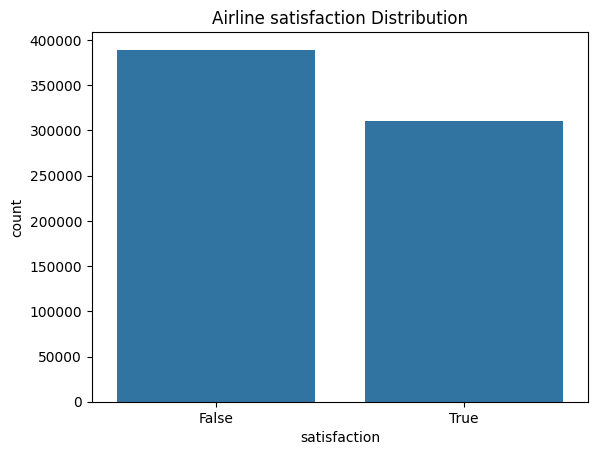

In [10]:
sns.countplot(data=df_train, x="satisfaction")
plt.title("Airline satisfaction Distribution")
plt.show()

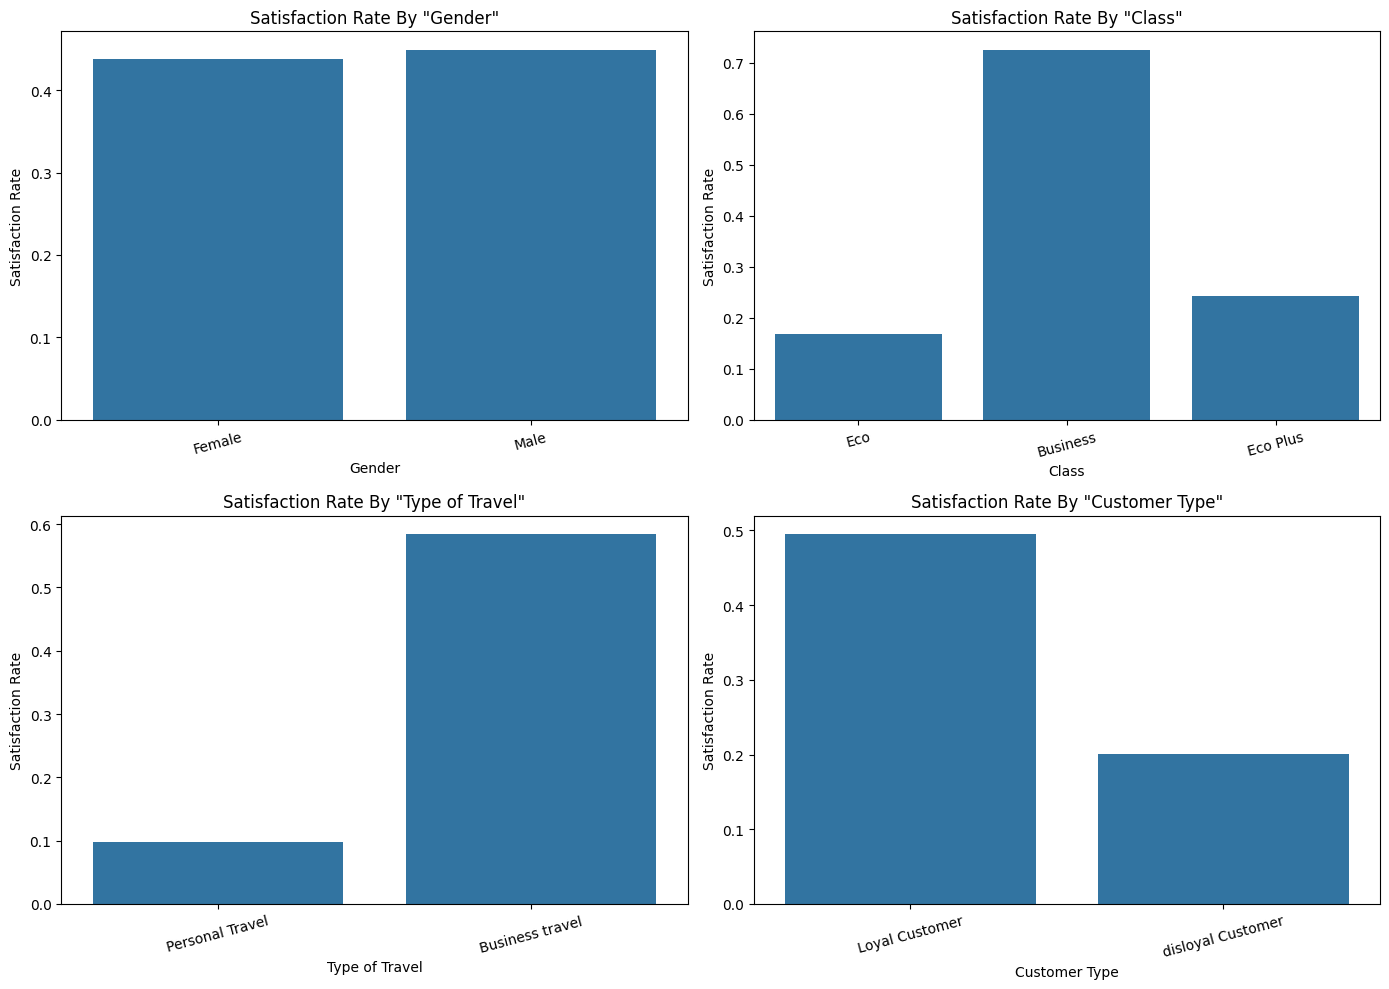

In [11]:
cat_cols = ["Gender", "Class", "Type of Travel", "Customer Type"]

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()  # Flatten to easily iterate through axes with a single loop

for i, col in enumerate(cat_cols):
    
    # Plot on the specific subplot axis
    sns.barplot(data=df_train, x=col, y="satisfaction", errorbar=None, ax=axes[i])
    axes[i].set_title(f"Satisfaction Rate By \"{col}\"")
    axes[i].set_ylabel("Satisfaction Rate")
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## Analyze airline service rating

In [12]:
print("df_train_list\n", df_train_list, "\n")

df_train_list
 ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction'] 



In [13]:
service_feature = ["service", "comfort", "food", "drink", "cleanliness", "entertainment", "boarding", "wifi", "check-in", "checkin", "online booking", "leg room"]

ser_fest = []
print("Service-related columns:")
for col in df_train.columns:
    # check if any keyword in service_feature is a substring of the column name
    if any(feat in col.lower() for feat in service_feature):
        ser_fest.append(col)
        print(f"-{col}")

Service-related columns:
-Inflight wifi service
-Ease of Online booking
-Food and drink
-Online boarding
-Seat comfort
-Inflight entertainment
-On-board service
-Leg room service
-Checkin service
-Cleanliness


In [14]:
print(ser_fest)

['Inflight wifi service', 'Ease of Online booking', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Checkin service', 'Cleanliness']


In [15]:
comparison = df_train.groupby("satisfaction")[ser_fest].mean().T
print(comparison.round(2))

satisfaction            False  True 
Inflight wifi service    2.45   3.20
Ease of Online booking   2.59   3.10
Food and drink           3.01   3.58
Online boarding          2.72   4.17
Seat comfort             3.11   4.14
Inflight entertainment   2.95   4.09
On-board service         3.13   4.00
Leg room service         3.10   3.94
Checkin service          3.15   3.76
Cleanliness              2.99   3.87


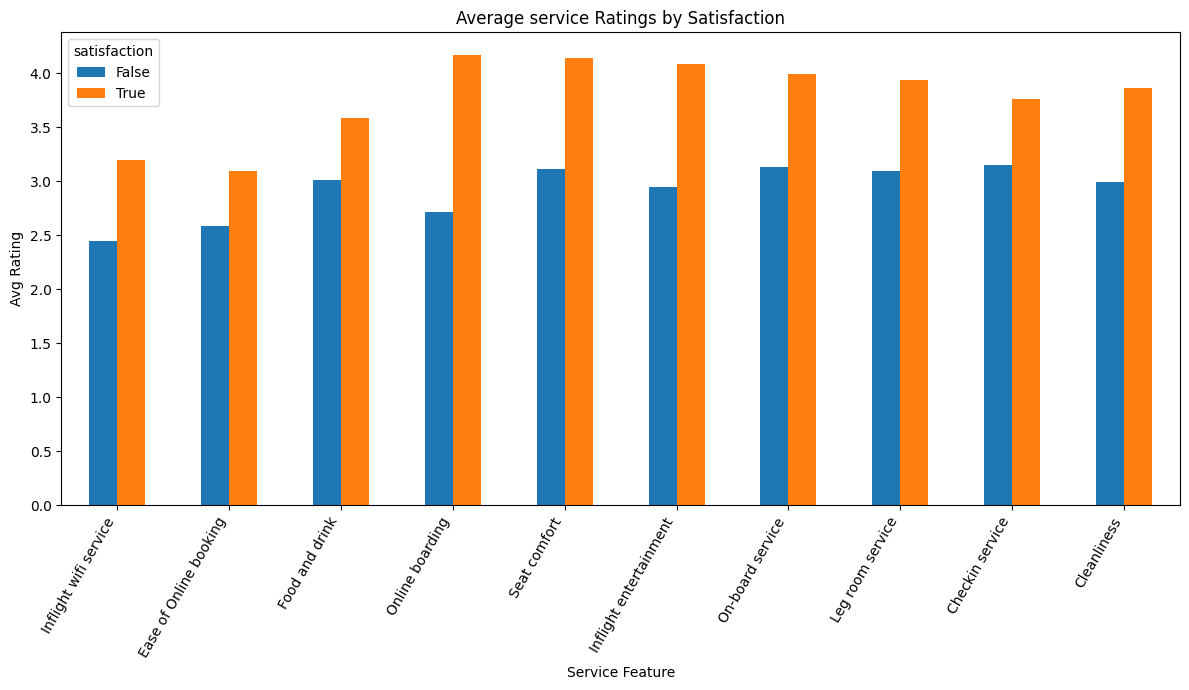

In [16]:
#Visualize the difference

comparison.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Average service Ratings by Satisfaction")
plt.ylabel("Avg Rating")
plt.xlabel("Service Feature")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## Analyze flight delayes

In [17]:
delay_feature = ["Departure Delay in Minutes",
                  "Arrival Delay in Minutes"
                  ]

delay_fest = []
print("Delay-related columns:")
for col in df_train.columns:
    # check if any keyword in delay_feature is a substring of the column name
    if any(feat.lower() in col.lower() for feat in delay_feature):
        delay_fest.append(col)
        print(f"-{col}")

Delay-related columns:
-Departure Delay in Minutes
-Arrival Delay in Minutes


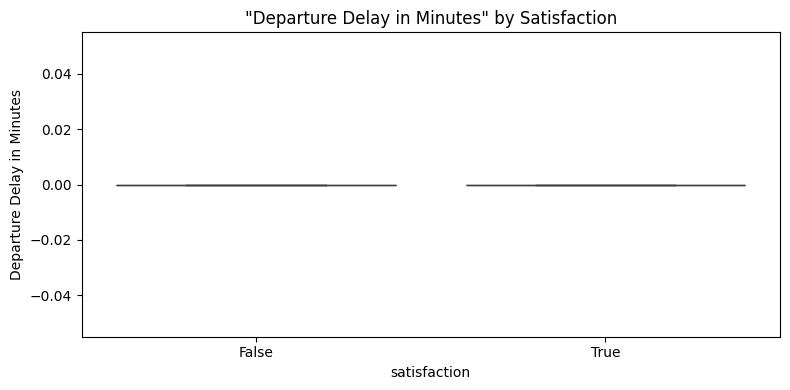

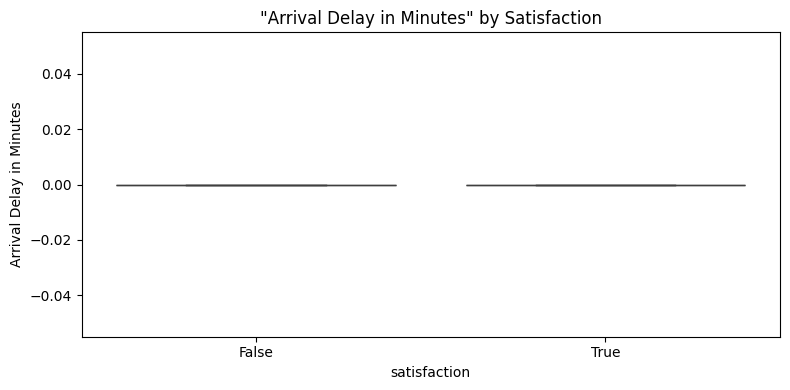

In [18]:
# Visualize the distribution

for col in delay_fest:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df_train,
        x="satisfaction",
        y=col,
        showfliers=False
    )

    plt.title(f"\"{col}\" by Satisfaction")
    plt.tight_layout()
    plt.show()

## Analyze numerical feature

In [19]:
num_cols = df_train.select_dtypes(include="number").columns.tolist()

for col in num_cols:
    if col == "id":
        num_cols.remove(col)
print(num_cols)

['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


In [20]:
# summary statistics
display(df_train[num_cols].describe().drop("count").T.round(2))

,mean,std,min,25%,50%,75%,max
Age,39.00,13.80,7.0,27.0,40.0,50.0,85.0
Flight Distance,1353.78,954.42,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,2.78,1.28,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,3.16,1.48,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,2.81,1.33,0.0,2.0,3.0,4.0,5.0
Gate location,3.01,1.25,0.0,2.0,3.0,4.0,5.0
Food and drink,3.27,1.30,0.0,2.0,3.0,4.0,5.0
Online boarding,3.36,1.29,0.0,2.0,4.0,4.0,5.0
Seat comfort,3.57,1.28,0.0,3.0,4.0,5.0,5.0
Inflight entertainment,3.45,1.31,0.0,2.0,4.0,5.0,5.0


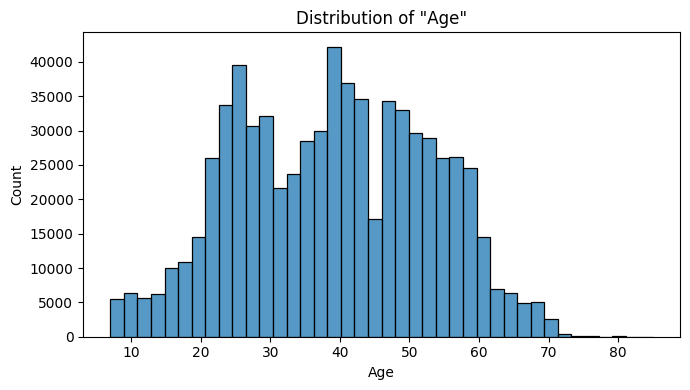

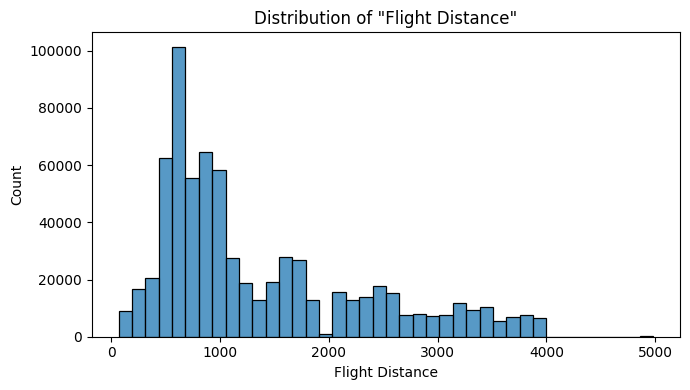

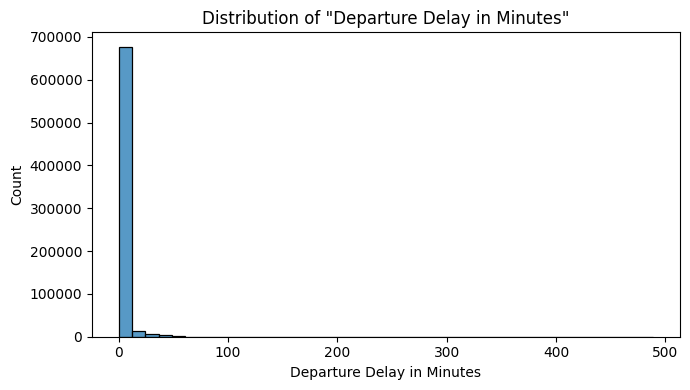

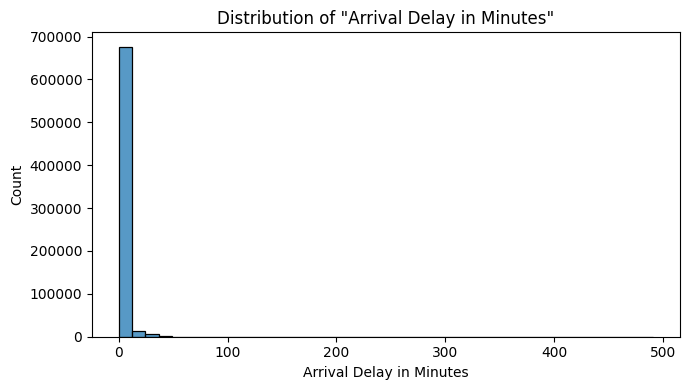

In [21]:
# plot bumerical distribution

features_to_plot = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]

for col in features_to_plot:
    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df_train,
        x=col,
        bins=40,
        kde=False
    )

    plt.title(f"Distribution of \"{col}\"")
    plt.tight_layout()
    plt.show()

## Correlation analysis

In [22]:
# Include the Boolean target as a numeric variable
corr_data = df_train[num_cols].copy()
corr_data["satisfaction"] = (
    df_train["satisfaction"].astype(int)
)

correlation = corr_data.corr(numeric_only=True)

# show correlation with the target
target_corr = (
    correlation["satisfaction"].drop("satisfaction").sort_values(ascending=False)
)

display(target_corr.to_frame("Correlation with satisfaction").round(3))

,Correlation with satisfaction
Online boarding,0.560
Inflight entertainment,0.431
Seat comfort,0.401
Flight Distance,0.370
On-board service,0.347
Cleanliness,0.339
Leg room service,0.330
Inflight wifi service,0.291
Baggage handling,0.258
Checkin service,0.250


In [23]:
top_features = target_corr.abs().nlargest(15).index
print(top_features)

Index(['Online boarding', 'Inflight entertainment', 'Seat comfort',
       'Flight Distance', 'On-board service', 'Cleanliness',
       'Leg room service', 'Inflight wifi service', 'Baggage handling',
       'Checkin service', 'Food and drink', 'Age', 'Ease of Online booking',
       'Arrival Delay in Minutes', 'Departure/Arrival time convenient'],
      dtype='object')


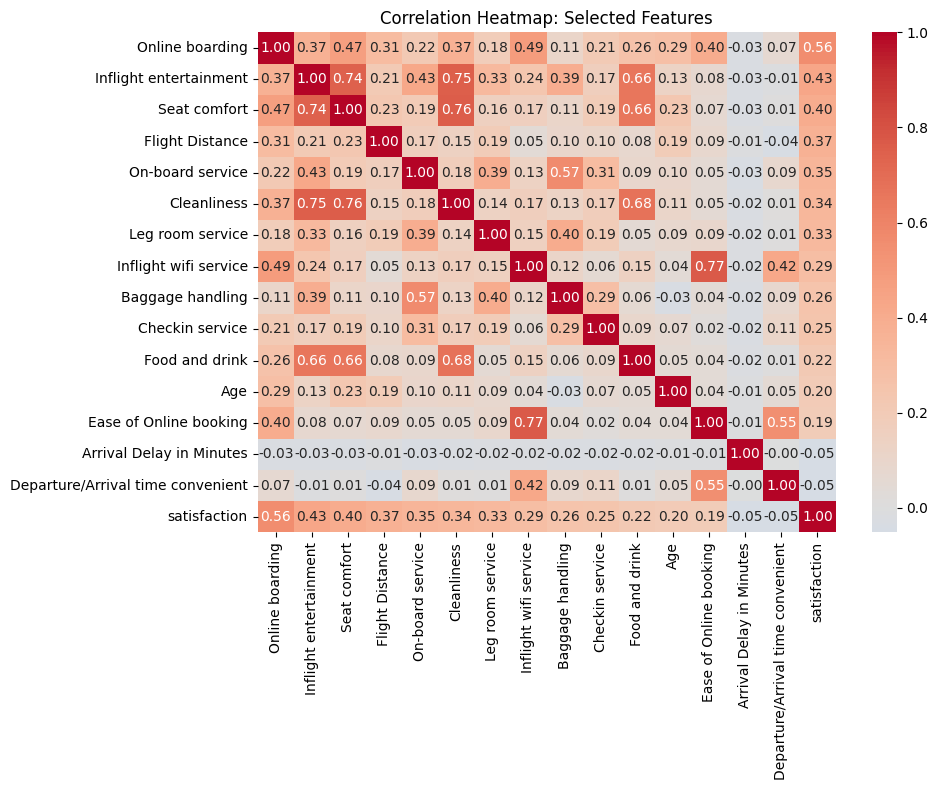

In [24]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_data[top_features.tolist() + ["satisfaction"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap: Selected Features")
plt.tight_layout()
plt.show()

## EDA Conclusion

In [25]:
eda_summary = {
    "training_rows": df_train.shape[0],
    "traing_colums": df_train.shape[1],
    "test_rows": df_test.shape[0],
    "missing_train_values": int(df_train.isnull().sum().sum()),
    "duplication_train_rows": int(df_train.isnull().sum().sum()),
    "satisfied_percentage": round(df_train["satisfaction"].mean()*100, 2),
    "not_satisfaction_percentage": round(1-df_train["satisfaction"].mean()*100,2)
}

for key, value in eda_summary.items():
    print(f"{key}: {value}")

training_rows: 699635
traing_colums: 23
test_rows: 299844
missing_train_values: 292
duplication_train_rows: 292
satisfied_percentage: 44.36
not_satisfaction_percentage: -43.36


## Data Preprocessing

### Seperate features and target

In [26]:
X = df_train.drop(columns=["satisfaction", "id"])
y = df_train["satisfaction"].astype(int)

# saving test IDs for final submission
test_ids = df_test["id"].copy()
X_df_test = df_test.drop(columns = "id")

# now identify the columns types
cat_features = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
num_features = X.select_dtypes(include=["number"]).columns.tolist()

print(f"X sahpe: {X.shape}")
print(f"y sahpe: {y.shape}")
print(f"No. of categorical calumns: {len(cat_features)}")
print(f"No. of numerical calumns: {len(num_features)}")
print("-"*70)
print(f"categorical calumns:\n{cat_features}")
print("-"*110)
print(f"numerical calumns:\n{num_features}")

X sahpe: (699635, 21)
y sahpe: (699635,)
No. of categorical calumns: 4
No. of numerical calumns: 17
----------------------------------------------------------------------
categorical calumns:
['Gender', 'Customer Type', 'Type of Travel', 'Class']
--------------------------------------------------------------------------------------------------------------
numerical calumns:
['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


## Splitting data and building pipeline
*We train and test different types of ML models for better predictions*

### Logistic Regression

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y
                                                   )

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numerical preprocessing
category_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

#combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_features),
    ("cat", category_pipeline, cat_features)
])

# complete model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=5000))
])

print("Preprocessing and model pipeline ready!")

Preprocessing and model pipeline ready!


In [28]:
# Train the model
model.fit(X_train, y_train)
y_pred = model.predict(X_test)


print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"F1 binary: {f1_score(y_test, y_pred)}")
print(f"F1 macro: {f1_score(y_test, y_pred, average="macro")}")
print(f"F1 weighted: {f1_score(y_test, y_pred, average="weighted")}")
print("-"*80)
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("-"*70)
print(classification_report(y_test, y_pred))

Accuracy: 0.8780864307817647
F1 binary: 0.8602923713197658
F1 macro: 0.8760761123155194
F1 weighted: 0.8778573343388884
--------------------------------------------------------------------------------

Confusion matrix:
[[70345  7514]
 [ 9545 52523]]
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.88      0.90      0.89     77859
           1       0.87      0.85      0.86     62068

    accuracy                           0.88    139927
   macro avg       0.88      0.87      0.88    139927
weighted avg       0.88      0.88      0.88    139927



### Random Forest Classifier

In [29]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators = 50,
        max_depth=14,
        min_samples_leaf=3,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    ))
])

print("Random forest training started...")
start = time.time()

rf_model.fit(X_train, y_train)

training_time = time.time() - start
print("Training completed")

Random forest training started...
Training completed


In [30]:
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_proba)

print("\n======= Random Forest Result============")

print("Accuracy: ", round(rf_accuracy, 5))
print("F1 Score: ", round(rf_f1, 5))
print("ROC-AUC: ", round(rf_auc, 5))
print("Training Time: ", round(training_time, 1), "seconds")

print("===========================================")


======= Random Forest Result============
Accuracy:  0.92153
F1 Score:  0.91073
ROC-AUC:  0.95541
Training Time:  22.7 seconds


## Gradient Boosting Classifier

In [31]:
gbc_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.08,
    max_depth=3,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=42
))
])


print("Gradient Boosting training started...")
start = time.time()

gbc_model.fit(X_train, y_train)

training_time = time.time() - start
print("Training completed")

Gradient Boosting training started...
Training completed


In [32]:
gbc_pred = gbc_model.predict(X_test)
gbc_proba = gbc_model.predict_proba(X_test)[:, 1]

gbc_accuracy = accuracy_score(y_test, gbc_pred)
gbc_f1 = f1_score(y_test, gbc_pred)
gbc_auc = roc_auc_score(y_test, gbc_proba)

print("\n======= Gradient Boosting Result============")

print("Accuracy: ", round(gbc_accuracy, 5))
print("F1 Score: ", round(gbc_f1, 5))
print("ROC-AUC: ", round(gbc_auc, 5))
print("Training Time: ", round(training_time, 1), "seconds")

print("===========================================")


======= Gradient Boosting Result============
Accuracy:  0.911
F1 Score:  0.89837
ROC-AUC:  0.95116
Training Time:  141.7 seconds


## Gausian Naive Bayes'

In [33]:
gnb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB()
    )
])


print("GausianNB training started...")
start = time.time()

gnb_model.fit(X_train, y_train)

training_time = time.time() - start
print("Training completed")

GausianNB training started...
Training completed


In [34]:
gnb_pred = gnb_model.predict(X_test)
gnb_proba = gnb_model.predict_proba(X_test)[:, 1]

gnb_accuracy = accuracy_score(y_test, gnb_pred)
gnb_f1 = f1_score(y_test, gnb_pred)
gnb_auc = roc_auc_score(y_test, gnb_proba)

print("\n======= Gaussian Naive Bayes' Result============")

print("Accuracy: ", round(gnb_accuracy, 5))
print("F1 Score: ", round(gnb_f1, 5))
print("ROC-AUC: ", round(gnb_auc, 5))
print("Training Time: ", round(training_time, 1), "seconds")

print("===========================================")


======= Gaussian Naive Bayes' Result============
Accuracy:  0.84931
F1 Score:  0.82862
ROC-AUC:  0.90622
Training Time:  2.6 seconds


## CatBoost Classifier

In [35]:
cbc_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", CatBoostClassifier(
        iterations=100,
        learning_rate=0.1,
        depth=6,
        verbose=0
    )
    )
])


print("CatBoostClassifier training started...")
start = time.time()

cbc_model.fit(X_train, y_train)

training_time = time.time() - start
print("Training completed")

CatBoostClassifier training started...
Training completed


In [36]:
cbc_pred = cbc_model.predict(X_test)
cbc_proba = cbc_model.predict_proba(X_test)[:, 1]

cbc_accuracy = accuracy_score(y_test, cbc_pred)
cbc_f1 = f1_score(y_test, cbc_pred)
cbc_auc = roc_auc_score(y_test, cbc_proba)

print("\n======= CatBoost Result============")

print("Accuracy: ", round(cbc_accuracy, 5))
print("F1 Score: ", round(cbc_f1, 5))
print("ROC-AUC: ", round(cbc_auc, 5))
print("Training Time: ", round(training_time, 1), "seconds")

print("===========================================")


======= CatBoost Result============
Accuracy:  0.92185
F1 Score:  0.91092
ROC-AUC:  0.95533
Training Time:  10.3 seconds


## The Best model

In [37]:
# Dictionary to store ROU_AUC values to pick best one
auc_score = {
    "Random Forest": rf_auc,
    "Gradient Boosting": gbc_auc,
    "Gausian Naive Bayes": gnb_auc,
    "CatBoost": cbc_auc
}

best_model = max(auc_score, key=auc_score.get)
print(f"The best model is \"{best_model}\" with a ROC-AUC score of \"{round(auc_score[best_model], 5)}\"")

The best model is "Random Forest" with a ROC-AUC score of "0.95541"


## Final Submission & Conclusion

In [38]:
# Train full training data
X = df_train.drop(columns=["satisfaction", "id"])
y = df_train["satisfaction"].astype(int)

# prepare the kaggle test data
X_test = df_test.drop(columns=["id"])
test_ids = df_test["id"]

# Train Random Forest on all training rows
rf_model.fit(X, y)

# predict satisfaction probabilities
test_prob = rf_model.predict_proba(X_test)[:, 1]

# create submission file
submission = pd.DataFrame({
    "id": test_ids,
    "satisfaction": test_prob
})

submission.to_csv("submission.csv", index=False)

print("submission file created successfully")

submission file created successfully


In [39]:
print(f"Submission sahpe: {submission.shape}")
print(submission.head())
print(f"Missing values: {submission.isnull().sum().sum()}")
print(f"Probability range: {submission["satisfaction"].min()} to {submission["satisfaction"].max()}")

Submission sahpe: (299844, 2)
       id  satisfaction
0  699635      0.236028
1  699636      0.833572
2  699637      0.858203
3  699638      0.077026
4  699639      0.050334
Missing values: 0
Probability range: 0.010444072460306151 to 0.993541050987663
